In [1]:
%pip -q install xgboost shap

import io
import zipfile
import numpy as np
import pandas as pd

from google.colab import files
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

RANDOM_STATE = 42

print("Setup complete!")

Setup complete!


In [2]:
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one dataset ZIP or CSV.")

filename = next(iter(uploaded))
file_data = io.BytesIO(uploaded[filename])

if filename.lower().endswith(".zip"):
    with zipfile.ZipFile(file_data) as archive:
        csv_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
        ]

        if len(csv_files) != 1:
            raise ValueError("The ZIP must contain exactly one CSV.")

        with archive.open(csv_files[0]) as csv_file:
            df = pd.read_csv(csv_file, low_memory=False)

elif filename.lower().endswith(".csv"):
    df = pd.read_csv(file_data, low_memory=False)

else:
    raise ValueError("Please upload a ZIP or CSV file.")

if not {"url", "status"}.issubset(df.columns):
    raise ValueError("Expected columns 'url' and 'status' are missing.")

print("Dataset shape:", df.shape)
print("\nLabel counts:")
print(df["status"].value_counts(dropna=False))

display(df.head())

Saving dataset_link_phishing.csv (1).zip to dataset_link_phishing.csv (1).zip
Dataset shape: (19431, 87)

Label counts:
status
legitimate    9716
phishing      9715
Name: count, dtype: int64


,Unnamed: 0,url,url_length,hostname_length,ip,total_of.,total_of-,total_of@,total_of?,total_of&,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,0,http://www.progarchives.com/album.asp?id=61737,46,20,0,3,0,0,1,0,...,1,one,0,627,6678,78526,0,0,5,phishing
1,1,http://signin.eday.co.uk.ws.edayisapi.dllsign....,128,120,0,10,0,0,0,0,...,1,zero,0,300,65,0,0,1,0,phishing
2,2,http://www.avevaconstruction.com/blesstool/ima...,52,25,0,3,0,0,0,0,...,1,zero,0,119,1707,0,0,1,0,phishing
3,3,http://www.jp519.com/,21,13,0,2,0,0,0,0,...,1,one,0,130,1331,0,0,0,0,legitimate
4,4,https://www.velocidrone.com/,28,19,0,2,0,0,0,0,...,0,zero,0,164,1662,312044,0,0,4,legitimate


In [3]:
# Encode the target: legitimate = 0, phishing = 1
labels = df["status"].astype(str).str.strip().str.lower()
y = labels.map({"legitimate": 0, "phishing": 1})

if y.isna().any():
    raise ValueError("Missing or unexpected labels found.")

# Remove the target, raw URL, and saved index columns
drop_columns = [
    column for column in df.columns
    if column in ["url", "status"]
    or str(column).lower().startswith("unnamed:")
]

X = df.drop(columns=drop_columns).copy()

# Convert text-encoded binary values and other numeric columns
for column in X.columns:
    values = X[column]

    if not pd.api.types.is_numeric_dtype(values):
        values = (
            values.astype("string")
            .str.strip()
            .str.lower()
            .replace({"zero": "0", "one": "1"})
        )

    numeric_values = pd.to_numeric(values, errors="coerce")

    unexpected = values.notna() & numeric_values.isna()
    if unexpected.any():
        examples = values[unexpected].unique()[:5]
        raise ValueError(
            f"Unexpected values in {column}: {examples}"
        )

    X[column] = numeric_values

X = X.replace([np.inf, -np.inf], np.nan)

print("Features before removing constant columns:", X.shape[1])
print("Missing feature values:", int(X.isna().sum().sum()))

constant_columns = X.columns[X.nunique(dropna=True) <= 1].tolist()
print("Constant or entirely missing columns:", constant_columns)

display(X.head())

Features before removing constant columns: 84
Missing feature values: 0
Constant or entirely missing columns: ['ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']


,url_length,hostname_length,ip,total_of.,total_of-,total_of@,total_of?,total_of&,total_of=,total_of_,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
0,46,20,0,3,0,0,1,0,1,0,...,0,1,1,0,627,6678,78526,0,0,5
1,128,120,0,10,0,0,0,0,0,0,...,1,1,0,0,300,65,0,0,1,0
2,52,25,0,3,0,0,0,0,0,0,...,0,1,0,0,119,1707,0,0,1,0
3,21,13,0,2,0,0,0,0,0,0,...,0,1,1,0,130,1331,0,0,0,0
4,28,19,0,2,0,0,0,0,0,0,...,0,0,0,0,164,1662,312044,0,0,4


In [4]:
# Split before fitting preprocessing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Learn replacement values from training data only
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train_raw)
X_test_imputed = imputer.transform(X_test_raw)

# Remove features that are constant in the training set
selector = VarianceThreshold(threshold=0.0)

X_train = selector.fit_transform(X_train_imputed)
X_test = selector.transform(X_test_imputed)

feature_names = X.columns[selector.get_support()].tolist()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Retained features:", len(feature_names))

print("\nClass counts (0 = legitimate, 1 = phishing):")
display(pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
}).sort_index())

Training shape: (13601, 79)
Testing shape: (5830, 79)
Retained features: 79

Class counts (0 = legitimate, 1 = phishing):


,Training,Testing
status,,
0,6801,2915
1,6800,2915


In [5]:
model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.3,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=2
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

our_results = {
    "Accuracy": accuracy_score(y_test, y_pred) * 100,
    "Precision": precision_score(y_test, y_pred, zero_division=0) * 100,
    "Recall": recall_score(y_test, y_pred, zero_division=0) * 100,
    "F1": f1_score(y_test, y_pred, zero_division=0) * 100
}

paper_results = {
    "Accuracy": 99.0,
    "Precision": 99.1,
    "Recall": 98.8,
    "F1": 99.0
}

comparison = pd.DataFrame({
    "Paper (%)": paper_results,
    "Our result (%)": our_results
})

comparison["Difference (percentage points)"] = (
    comparison["Our result (%)"] - comparison["Paper (%)"]
)

display(comparison.round(2))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Phishing"],
    digits=4,
    zero_division=0
))

,Paper (%),Our result (%),Difference (percentage points)
Accuracy,99.0,98.42,-0.58
Precision,99.1,98.69,-0.41
Recall,98.8,98.15,-0.65
F1,99.0,98.42,-0.58



Classification report:
              precision    recall  f1-score   support

  Legitimate     0.9816    0.9870    0.9843      2915
    Phishing     0.9869    0.9815    0.9842      2915

    accuracy                         0.9842      5830
   macro avg     0.9842    0.9842    0.9842      5830
weighted avg     0.9842    0.9842    0.9842      5830



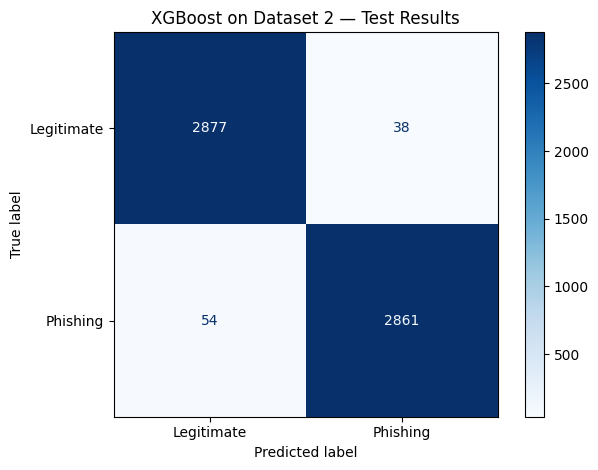

In [6]:
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues",
    values_format="d"
)

plt.title("XGBoost on Dataset 2 — Test Results")
plt.tight_layout()
plt.show()